# III. E-commerce Customer-Interest Discovery

**Dataset:** `Womens Clothing E-Commerce Reviews.csv` (https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews)

Các **features** là những thông tin đầu vào được dùng để dự đoán khách hàng có recommend sản phẩm hay không.

Trong bài này sử dụng các đặc trưng chính:

- `Age`: tuổi của khách hàng.
- `Title`: tiêu đề của review.
- `Review Text`: nội dung đánh giá của khách hàng.
- `Division Name`: nhóm sản phẩm lớn.
- `Department Name`: bộ phận hoặc nhóm sản phẩm.
- `Class Name`: loại sản phẩm cụ thể.

Hai cột `Title` và `Review Text` được ghép lại thành một biến văn bản `review`. Sau đó, nội dung review được chuyển thành vector số bằng **TF-IDF** để các mô hình có thể xử lý.

Các biến phân loại như `Division Name`, `Department Name` và `Class Name` được chuyển sang dạng số bằng **One-Hot Encoding**.

Các cột như `Unnamed: 0` và `Clothing ID` không được sử dụng vì chủ yếu là mã định danh. `Rating` cũng không được dùng làm feature vì nó có liên hệ rất trực tiếp với việc recommend sản phẩm và có thể gây **data leakage**.

**Outcome (Target)** của bài toán là:

- `Recommended IND`

Biến này có hai giá trị:

- `1`: khách hàng **recommend sản phẩm**.
- `0`: khách hàng **không recommend sản phẩm**.

Trong bài toán này, `Recommended IND = 1` được xem là biểu hiện cho thấy khách hàng có mức độ hài lòng hoặc quan tâm tích cực đến sản phẩm.

## 1. Import thư viện và đọc dữ liệu

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, mean_squared_error,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)

DATA_PATH = Path("Womens Clothing E-Commerce Reviews.csv")

if not DATA_PATH.is_file():
    DATA_PATH = Path(r':\Users\Dat\Downloads\PTHTTM\DATA\/Womens Clothing E-Commerce Reviews.csv')

df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 2. Kiểm tra dữ liệu

Chỉ kiểm tra các thông tin cần thiết: kích thước, số giá trị thiếu, số dòng trùng và phân bố outcome.

In [2]:
check_table = pd.DataFrame({
    "Thông tin": [
        "Số dòng",
        "Số cột",
        "Tổng ô bị thiếu",
        "Dòng trùng hoàn toàn"
    ],
    "Giá trị": [
        df.shape[0],
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum()
    ]
})

display(check_table)

target_table = (
    df["Recommended IND"]
    .value_counts()
    .sort_index()
    .rename_axis("Recommended IND")
    .reset_index(name="Số dòng")
)

display(target_table)

,Thông tin,Giá trị
0,Số dòng,23486
1,Số cột,11
2,Tổng ô bị thiếu,4697
3,Dòng trùng hoàn toàn,0


,Recommended IND,Số dòng
0,0,4172
1,1,19314


## 3. Feature và Outcome

### Features

Các đặc trưng được sử dụng:

- `Age`: tuổi khách hàng.
- `Title` + `Review Text`: nội dung đánh giá, được ghép thành một chuỗi `review`.
- `Division Name`: nhóm sản phẩm lớn.
- `Department Name`: phòng/nhóm sản phẩm.
- `Class Name`: loại sản phẩm cụ thể.

`Review Text` được chuyển thành vector số bằng **TF-IDF**. Các cột phân loại được chuyển thành số bằng **One-Hot Encoding**.

Các cột `Unnamed: 0` và `Clothing ID` chủ yếu là mã định danh nên không dùng. `Rating` không dùng làm feature vì nó có quan hệ rất gần với việc recommend và có thể làm bài toán quá dễ. `Positive Feedback Count` cũng không dùng vì đây là phản hồi xuất hiện sau khi review được đăng.

### Outcome

Outcome là `Recommended IND`:

- `1`: khách hàng recommend sản phẩm.
- `0`: khách hàng không recommend sản phẩm.

Đây là bài toán **Binary Classification**.

## 4. Làm sạch dữ liệu

Ta bỏ dòng trùng, điền chuỗi rỗng cho phần văn bản và điền `"Unknown"` cho các cột phân loại bị thiếu.

In [3]:
data = df.drop_duplicates().copy()

data["Title"] = data["Title"].fillna("")
data["Review Text"] = data["Review Text"].fillna("")

data["Division Name"] = data["Division Name"].fillna("Unknown")
data["Department Name"] = data["Department Name"].fillna("Unknown")
data["Class Name"] = data["Class Name"].fillna("Unknown")

data["review"] = data["Title"] + " " + data["Review Text"]

data = data[data["Recommended IND"].isin([0, 1])].copy()
data = data.reset_index(drop=True)

print("Số dòng sau làm sạch:", len(data))

Số dòng sau làm sạch: 23486


## 5. Biểu đồ phân bố Outcome

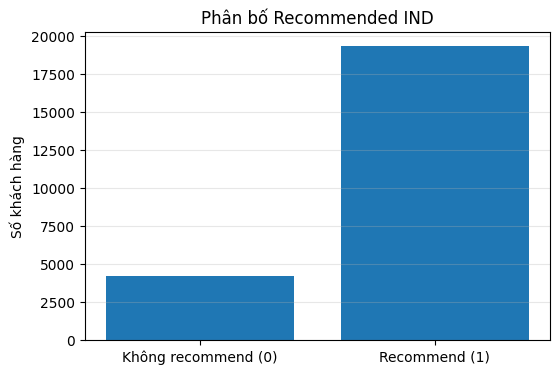

In [4]:
counts = data["Recommended IND"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Không recommend (0)", "Recommend (1)"], counts.values)
plt.ylabel("Số khách hàng")
plt.title("Phân bố Recommended IND")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** Dữ liệu có **4.172 mẫu không recommend** và **19.314 mẫu recommend**, tức lớp `1` chiếm khoảng **82,24%**. Dữ liệu bị lệch về lớp recommend, vì vậy không nên chỉ dựa vào Accuracy mà cần xem thêm Precision, Recall, F1 và ROC-AUC.

## 6. Chia Train / Validation / Test

Dữ liệu được chia theo tỷ lệ:

- Train: 70%
- Validation: 15%
- Test: 15%

Dùng `stratify` để giữ tỷ lệ hai lớp tương đối giống nhau.

In [5]:
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data["Recommended IND"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["Recommended IND"]
)

split_table = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số dòng": [len(train_df), len(val_df), len(test_df)],
    "Lớp 0": [
        (train_df["Recommended IND"] == 0).sum(),
        (val_df["Recommended IND"] == 0).sum(),
        (test_df["Recommended IND"] == 0).sum()
    ],
    "Lớp 1": [
        (train_df["Recommended IND"] == 1).sum(),
        (val_df["Recommended IND"] == 1).sum(),
        (test_df["Recommended IND"] == 1).sum()
    ],
    "Tỷ lệ lớp 1 (%)": [
        train_df["Recommended IND"].mean() * 100,
        val_df["Recommended IND"].mean() * 100,
        test_df["Recommended IND"].mean() * 100
    ]
})

display(
    split_table.style.format({
        "Số dòng": "{:,.0f}",
        "Lớp 0": "{:,.0f}",
        "Lớp 1": "{:,.0f}",
        "Tỷ lệ lớp 1 (%)": "{:.2f}%"
    })
)

,Tập dữ liệu,Số dòng,Lớp 0,Lớp 1,Tỷ lệ lớp 1 (%)
0,Train,"16,440","2,920","13,520",82.24%
1,Validation,"3,523",626,"2,897",82.23%
2,Test,"3,523",626,"2,897",82.23%


## 7. Biểu diễn dữ liệu

### Văn bản

`Title + Review Text` được chuyển thành **100 đặc trưng TF-IDF**.

### Tuổi

`Age` được chuẩn hóa bằng StandardScaler.

### Các biến phân loại

`Division Name`, `Department Name` và `Class Name` được chuyển thành các cột 0/1 bằng One-Hot Encoding.

Cuối cùng ghép tất cả lại thành một ma trận đầu vào chung cho cả 4 mô hình.

In [6]:
# 1. TF-IDF cho review
vectorizer = TfidfVectorizer(
    max_features=100,
    stop_words="english"
)

X_text_train = vectorizer.fit_transform(train_df["review"]).toarray()
X_text_val = vectorizer.transform(val_df["review"]).toarray()
X_text_test = vectorizer.transform(test_df["review"]).toarray()

# 2. Chuẩn hóa Age
scaler = StandardScaler()

X_age_train = scaler.fit_transform(train_df[["Age"]])
X_age_val = scaler.transform(val_df[["Age"]])
X_age_test = scaler.transform(test_df[["Age"]])

# 3. One-hot các cột phân loại
cat_cols = ["Division Name", "Department Name", "Class Name"]

X_cat_train = pd.get_dummies(train_df[cat_cols], dtype=float)
X_cat_val = pd.get_dummies(val_df[cat_cols], dtype=float)
X_cat_test = pd.get_dummies(test_df[cat_cols], dtype=float)

# Đảm bảo Validation/Test có đúng các cột giống Train
X_cat_val = X_cat_val.reindex(columns=X_cat_train.columns, fill_value=0)
X_cat_test = X_cat_test.reindex(columns=X_cat_train.columns, fill_value=0)

# 4. Ghép thành X
X_train = np.hstack([
    X_text_train,
    X_age_train,
    X_cat_train.values
]).astype(np.float32)

X_val = np.hstack([
    X_text_val,
    X_age_val,
    X_cat_val.values
]).astype(np.float32)

X_test = np.hstack([
    X_text_test,
    X_age_test,
    X_cat_test.values
]).astype(np.float32)

y_train = train_df["Recommended IND"].to_numpy()
y_val = val_df["Recommended IND"].to_numpy()
y_test = test_df["Recommended IND"].to_numpy()

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

X_train: (16440, 133)
X_val  : (3523, 133)
X_test : (3523, 133)


## 8. Các metrics đánh giá

Ta sử dụng:

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

$$
Precision = \frac{TP}{TP+FP}
$$

$$
Recall = \frac{TP}{TP+FN}
$$

$$
F1 = \frac{2 \times Precision \times Recall}{Precision + Recall}
$$

**ROC-AUC** đánh giá khả năng phân biệt hai lớp qua nhiều ngưỡng.

Theo yêu cầu bổ sung, ta còn hiển thị:

$$
MSE = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

Với bài toán phân loại 0/1, MSE chỉ là chỉ số bổ sung.

In [7]:
def evaluate_model(name, y_true, y_pred, y_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "MSE": mean_squared_error(y_true, y_pred)
    }

results = []
predictions = {}
scores = {}
models = {}

## 9. Model 1 - Logistic Regression

In [8]:
logistic_model = LogisticRegression(
    max_iter=500,
    random_state=SEED
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_val)
logistic_score = logistic_model.predict_proba(X_val)[:, 1]

results.append(
    evaluate_model(
        "Logistic Regression",
        y_val,
        logistic_pred,
        logistic_score
    )
)

predictions["Logistic Regression"] = logistic_pred
scores["Logistic Regression"] = logistic_score
models["Logistic Regression"] = logistic_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Logistic Regression,0.8541,0.8732,0.9624,0.9156,0.853,0.1459


## 10. Model 2 - Decision Tree

In [9]:
tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=15,
    random_state=SEED
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_val)
tree_score = tree_model.predict_proba(X_val)[:, 1]

results.append(
    evaluate_model(
        "Decision Tree",
        y_val,
        tree_pred,
        tree_score
    )
)

predictions["Decision Tree"] = tree_pred
scores["Decision Tree"] = tree_score
models["Decision Tree"] = tree_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Decision Tree,0.832,0.8543,0.9593,0.9037,0.7444,0.168


## 11. Model 3 - Random Forest

In [10]:
forest_model = RandomForestClassifier(
    n_estimators=80,
    max_depth=14,
    min_samples_leaf=8,
    random_state=SEED,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_val)
forest_score = forest_model.predict_proba(X_val)[:, 1]

results.append(
    evaluate_model(
        "Random Forest",
        y_val,
        forest_pred,
        forest_score
    )
)

predictions["Random Forest"] = forest_pred
scores["Random Forest"] = forest_score
models["Random Forest"] = forest_model

display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Random Forest,0.832,0.8322,0.9965,0.907,0.8395,0.168


# 12. Model 4 - Deep Learning 

Mạng được xây dựng:

```text
d đặc trưng → 16 → 8 → 1
```

Forward propagation:

$$
H_1 = ReLU(XW_1+b_1)
$$

$$
H_2 = ReLU(H_1W_2+b_2)
$$

$$
\hat{y} = \sigma(H_2W_3+b_3)
$$

### 12.1. Khởi tạo trọng số

In [11]:
d = X_train.shape[1]
rng = np.random.default_rng(SEED)

W1 = (rng.standard_normal((d, 16)) * np.sqrt(2 / d)).astype(np.float32)
b1 = np.zeros((1, 16), dtype=np.float32)

W2 = (rng.standard_normal((16, 8)) * np.sqrt(2 / 16)).astype(np.float32)
b2 = np.zeros((1, 8), dtype=np.float32)

W3 = (rng.standard_normal((8, 1)) * np.sqrt(2 / 8)).astype(np.float32)
b3 = np.zeros((1, 1), dtype=np.float32)

print("Kiến trúc:", d, "→ 16 → 8 → 1")
print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)

Kiến trúc: 133 → 16 → 8 → 1
W1: (133, 16)
W2: (16, 8)
W3: (8, 1)


### 12.2. ReLU, Sigmoid và Binary Cross-Entropy

$$
ReLU(z)=\max(0,z)
$$

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

$$
L=-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(\hat{y}_i)
+(1-y_i)\log(1-\hat{y}_i)
\right]
$$

In [12]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(np.float32)

def sigmoid(z):
    z = np.clip(z, -50, 50)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y, y_hat):
    y = y.reshape(-1, 1)
    y_hat = np.clip(y_hat, 1e-8, 1 - 1e-8)

    return -np.mean(
        y * np.log(y_hat)
        + (1 - y) * np.log(1 - y_hat)
    )

### 12.3. Forward propagation

In [13]:
def forward(X):
    z1 = X @ W1 + b1
    h1 = relu(z1)

    z2 = h1 @ W2 + b2
    h2 = relu(z2)

    z3 = h2 @ W3 + b3
    y_hat = sigmoid(z3)

    return y_hat, z1, h1, z2, h2

### 12.4. Backpropagation

Với Sigmoid + Binary Cross-Entropy:

$$
dZ_3 = \frac{\hat{y}-y}{N}
$$

Sau đó cập nhật trọng số bằng Gradient Descent:

$$
W \leftarrow W-\eta dW
$$

In [14]:
def backward(X, y, y_hat, z1, h1, z2, h2):
    y = y.reshape(-1, 1)
    n = len(X)

    dz3 = (y_hat - y) / n
    dW3 = h2.T @ dz3
    db3 = np.sum(dz3, axis=0, keepdims=True)

    dh2 = dz3 @ W3.T
    dz2 = dh2 * relu_derivative(z2)
    dW2 = h1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dh1 = dz2 @ W2.T
    dz1 = dh1 * relu_derivative(z1)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3

### 12.5. Huấn luyện mạng NumPy

Mỗi epoch:

```text
Forward → Loss → Backpropagation → Update
```

In [15]:
learning_rate = 0.05
epochs = 50
batch_size = 512

train_loss_history = []
val_loss_history = []

for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))

    for start in range(0, len(indices), batch_size):

        batch_idx = indices[start:start + batch_size]

        X_batch = X_train[batch_idx]
        y_batch = y_train[batch_idx]

        y_hat, z1, h1, z2, h2 = forward(X_batch)

        dW1, db1, dW2, db2, dW3, db3 = backward(
            X_batch, y_batch, y_hat,
            z1, h1, z2, h2
        )

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

    train_prob, *_ = forward(X_train)
    val_prob, *_ = forward(X_val)

    train_loss = binary_cross_entropy(y_train, train_prob)
    val_loss = binary_cross_entropy(y_val, val_prob)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:2d} | "
            f"Train Loss = {train_loss:.4f} | "
            f"Val Loss = {val_loss:.4f}"
        )

Epoch  1 | Train Loss = 0.5543 | Val Loss = 0.5532


Epoch 10 | Train Loss = 0.4668 | Val Loss = 0.4664


Epoch 20 | Train Loss = 0.4602 | Val Loss = 0.4603


Epoch 30 | Train Loss = 0.4492 | Val Loss = 0.4504


Epoch 40 | Train Loss = 0.4266 | Val Loss = 0.4301


Epoch 50 | Train Loss = 0.3904 | Val Loss = 0.3965


### 12.6. Biểu đồ Loss

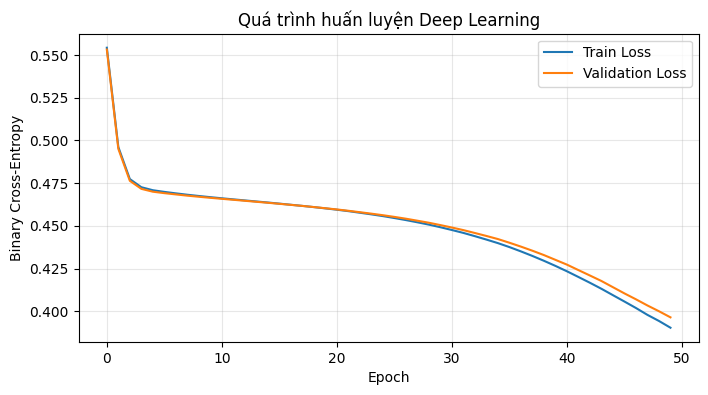

In [16]:
plt.figure(figsize=(8, 4))

plt.plot(train_loss_history, label="Train Loss")
plt.plot(val_loss_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Quá trình huấn luyện Deep Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** Train Loss giảm từ khoảng **0,5543** xuống **0,3904**, còn Validation Loss giảm từ khoảng **0,5532** xuống **0,3965**. Hai đường cùng giảm và khá gần nhau nên mạng có học được từ dữ liệu; chưa thấy dấu hiệu overfitting mạnh trong 50 epoch.

### 12.7. Đánh giá Deep Learning

In [17]:
dl_score = forward(X_val)[0].ravel()
dl_pred = (dl_score >= 0.5).astype(int)

results.append(
    evaluate_model(
        "Deep Learning NumPy",
        y_val,
        dl_pred,
        dl_score
    )
)

predictions["Deep Learning NumPy"] = dl_pred
scores["Deep Learning NumPy"] = dl_score

display(pd.DataFrame([results[-1]]).round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Deep Learning NumPy,0.8223,0.8223,1.0,0.9025,0.8114,0.1777


## 13. Bảng so sánh 4 mô hình

- Accuracy, Precision, Recall, F1 và ROC-AUC: **càng cao càng tốt**.
- MSE: **càng thấp càng tốt**.

Mô hình được sắp xếp theo F1 trên Validation Set.

In [18]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "MSE": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Logistic Regression,0.8541,0.8732,0.9624,0.9156,0.8530,0.1459
1,Random Forest,0.8320,0.8322,0.9965,0.9070,0.8395,0.1680
2,Decision Tree,0.8320,0.8543,0.9593,0.9037,0.7444,0.1680
3,Deep Learning NumPy,0.8223,0.8223,1.0000,0.9025,0.8114,0.1777


### 13.1. Biểu đồ so sánh 5 metrics chính

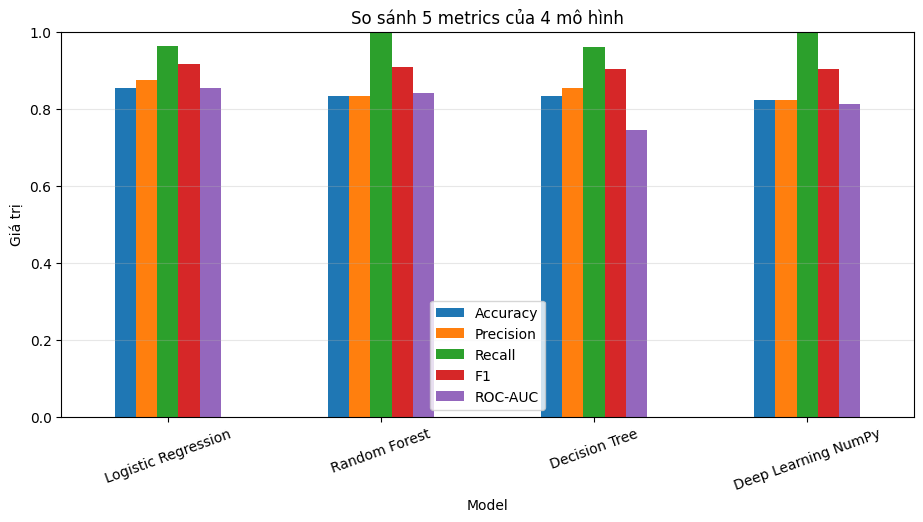

In [19]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.ylim(0, 1)
plt.ylabel("Giá trị")
plt.title("So sánh 5 metrics của 4 mô hình")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** **Logistic Regression** có F1 cao nhất khoảng **0,9156** và ROC-AUC khoảng **0,8530**. Random Forest có Recall rất cao (**0,9965**) nhưng Precision thấp hơn. Deep Learning NumPy đạt Recall = **1,0** nhưng Precision chỉ khoảng **0,8223**, cho thấy ở ngưỡng 0,5 mạng đang dự đoán gần như toàn bộ mẫu thành lớp recommend.

### 13.2. Biểu đồ MSE

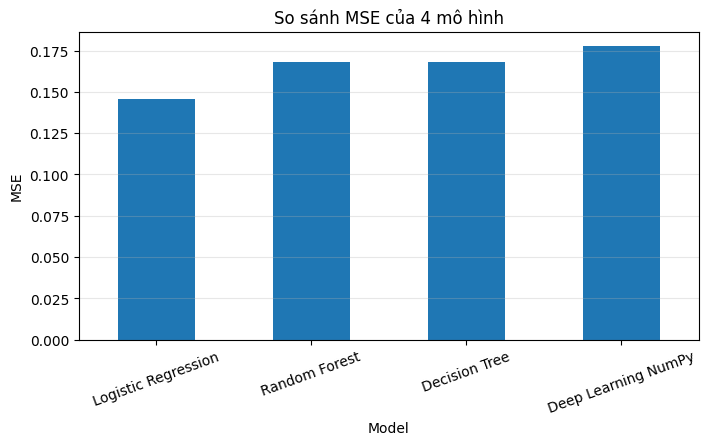

In [20]:
comparison_df.set_index("Model")["MSE"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.ylabel("MSE")
plt.title("So sánh MSE của 4 mô hình")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** **Logistic Regression** có MSE thấp nhất, khoảng **0,1459**. Decision Tree và Random Forest đều khoảng **0,1680**, còn Deep Learning NumPy khoảng **0,1777**. Với bài toán phân loại 0/1, MSE chỉ là chỉ số bổ sung; giá trị càng thấp càng tốt.

### 13.3. ROC Curve

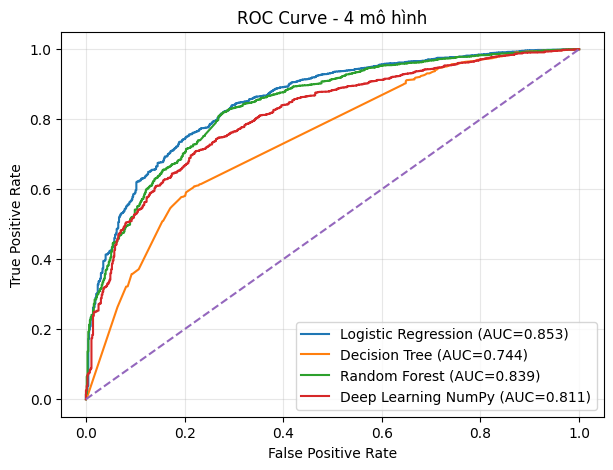

In [21]:
plt.figure(figsize=(7, 5))

for name in scores:
    fpr, tpr, _ = roc_curve(y_val, scores[name])
    auc = roc_auc_score(y_val, scores[name])

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - 4 mô hình")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Nhận xét biểu đồ:** Logistic Regression có ROC-AUC cao nhất khoảng **0,8530**, tiếp theo là Random Forest (**0,8395**), Deep Learning NumPy (**0,8114**) và Decision Tree (**0,7444**). Đường ROC của Logistic Regression nằm cao hơn phần lớn các mô hình còn lại nên khả năng phân biệt hai lớp tốt nhất trong lần chạy này.

## 14. Confusion Matrix của 4 mô hình

### 14.1. Logistic Regression

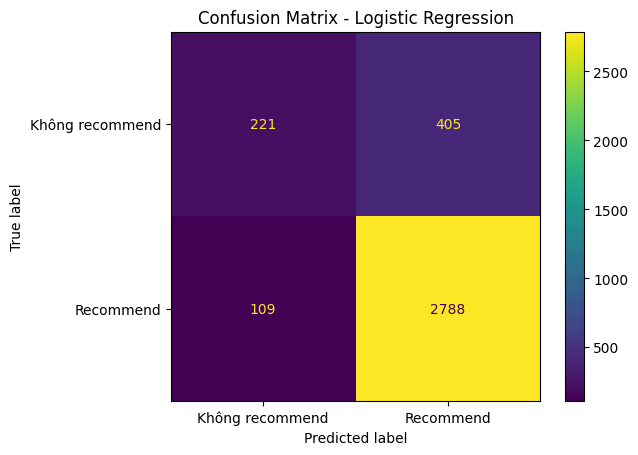

In [22]:
cm = confusion_matrix(
    y_val,
    predictions["Logistic Regression"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Không recommend", "Recommend"]
).plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

**Nhận xét biểu đồ:** Logistic Regression đạt **Precision ≈ 0,8732**, **Recall ≈ 0,9624** và **F1 ≈ 0,9156**. Mô hình nhận diện phần lớn khách hàng recommend, đồng thời vẫn giữ số dự đoán nhầm ở mức thấp hơn các mô hình có Recall gần 1.

### 14.2. Decision Tree

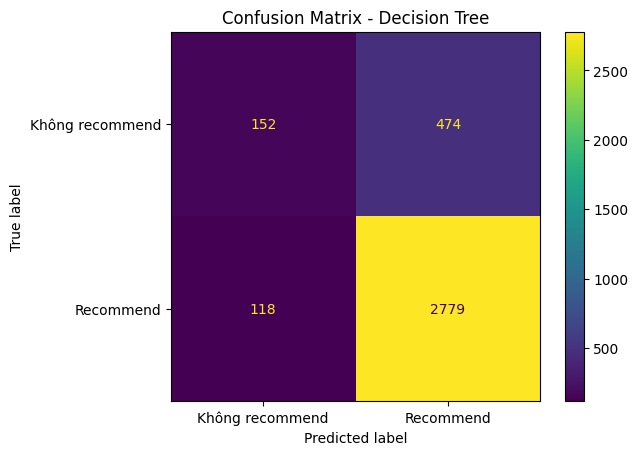

In [23]:
cm = confusion_matrix(
    y_val,
    predictions["Decision Tree"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Không recommend", "Recommend"]
).plot()

plt.title("Confusion Matrix - Decision Tree")
plt.show()

**Nhận xét biểu đồ:** Decision Tree có **Recall ≈ 0,9593** nhưng Precision khoảng **0,8543**. Mô hình phát hiện được nhiều trường hợp recommend nhưng vẫn có nhiều mẫu không recommend bị dự đoán nhầm thành recommend, làm F1 chỉ khoảng **0,9037**.

### 14.3. Random Forest

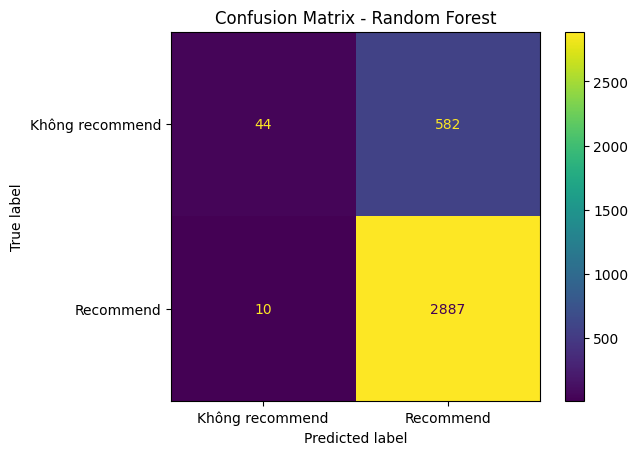

In [24]:
cm = confusion_matrix(
    y_val,
    predictions["Random Forest"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Không recommend", "Recommend"]
).plot()

plt.title("Confusion Matrix - Random Forest")
plt.show()

**Nhận xét biểu đồ:** Random Forest có Recall rất cao, khoảng **0,9965**, tức gần như không bỏ sót khách hàng recommend. Tuy nhiên Precision chỉ khoảng **0,8322**, cho thấy mô hình dự đoán lớp recommend khá rộng và tạo nhiều False Positive hơn Logistic Regression.

### 14.4. Deep Learning NumPy

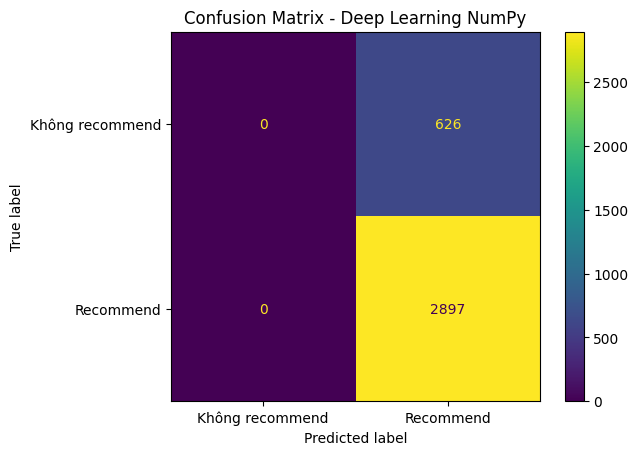

In [25]:
cm = confusion_matrix(
    y_val,
    predictions["Deep Learning NumPy"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Không recommend", "Recommend"]
).plot()

plt.title("Confusion Matrix - Deep Learning NumPy")
plt.show()

**Nhận xét biểu đồ:** Deep Learning NumPy có **Recall = 1,0** và Precision khoảng **0,8223**. Điều này cho thấy tại ngưỡng 0,5 mạng dự đoán gần như tất cả mẫu thành `Recommend`. Vì dữ liệu vốn có khoảng 82% lớp `1`, Accuracy và F1 vẫn khá cao nhưng khả năng phân biệt hai lớp tại ngưỡng này chưa tốt bằng Logistic Regression.

## 15. Chọn mô hình tốt nhất

Chọn mô hình có **F1 cao nhất trên Validation Set**.

In [26]:
best_name = comparison_df.iloc[0]["Model"]

print("Mô hình tốt nhất theo Validation F1:", best_name)
display(comparison_df.iloc[[0]])

Mô hình tốt nhất theo Validation F1: Logistic Regression


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Logistic Regression,0.854102,0.87316,0.962375,0.915599,0.853012,0.145898


## 16. Đánh giá 4 mô hình trên Test Set

Sau khi hoàn thành so sánh trên Validation Set, ta đánh giá lại cả 4 mô hình trên Test Set để xem kết quả có ổn định hay không.

In [27]:
test_results = []

for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:

    model = models[name]

    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]

    test_results.append(
        evaluate_model(
            name,
            y_test,
            pred,
            score
        )
    )

# Deep Learning
dl_test_score = forward(X_test)[0].ravel()
dl_test_pred = (dl_test_score >= 0.5).astype(int)

test_results.append(
    evaluate_model(
        "Deep Learning NumPy",
        y_test,
        dl_test_pred,
        dl_test_score
    )
)

test_df_result = pd.DataFrame(test_results).sort_values(
    "F1",
    ascending=False
)

display(test_df_result.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,MSE
0,Logistic Regression,0.8541,0.8739,0.9613,0.9155,0.8583,0.1459
2,Random Forest,0.8263,0.8290,0.9938,0.9039,0.8418,0.1737
3,Deep Learning NumPy,0.8223,0.8223,1.0000,0.9025,0.8146,0.1777
1,Decision Tree,0.8271,0.8514,0.9569,0.9010,0.7459,0.1729


### Nhận xét kết quả Test Set

Trên Test Set, **Logistic Regression tiếp tục có F1 cao nhất, khoảng 0,9155**, Accuracy khoảng **0,8541** và ROC-AUC khoảng **0,8583**. Kết quả gần với Validation Set nên mô hình khá ổn định.

Deep Learning NumPy đạt Recall = **1,0** nhưng Precision khoảng **0,8223**, cho thấy mạng vẫn thiên mạnh về dự đoán lớp recommend. Với cấu hình đơn giản hiện tại, Logistic Regression phù hợp hơn cho bài toán này.